You are provided with the Geron’s notebook from chapter 18 of his PyTorch book, 
18_autoencoders_gans_and_diffusion_models.ipynb.Please create your own 
notebook only with your solutions to the following problems. Please do not submit 
modified version of Geron’s notebook. 

## Problem 1.  
Plots of training data on slides 24 and 28 are actually from another example and not from the above notebook. Use the following code to generate a new set of 3D data X_train : 

```
import numpy as np 
np.random.seed(4) 
def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1): 
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5 
    data = np.empty((m, 3)) 
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2 
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2 
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m) 
    return data 
 
X_train = generate_3d_data(60) 
X_train = X_train - X_train.mean(axis=0, keepdims=0) 
```
 
Create validation data, train the autoencoder with code given on slide 25 and plot resulting 2D codings

In [ ]:
# setup
import numpy as np 
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotly.express as px
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torchmetrics
from mpl_toolkits.mplot3d import Axes3D
np.random.seed(4) 
torch.manual_seed(42)

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cuda'

In [7]:
#the code in this cell is directly from the Geron’s notebook -- do i need to modify it?
def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=2, factor=0.5, epoch_callback=None):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss/(index+1):.4f}", end="")
            print(f", {train_metric=:.3f}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"\rEpoch {epoch + 1}/{n_epochs},                      "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.3}, "
              f"valid metric: {history['valid_metrics'][-1]:.3}")
    return history

x_train: (60, 3)


x_valid: (500, 3)
ok
Epoch 1/20,                      train loss: 0.4854, train metric: 0.706, valid metric: 0.284
Epoch 2/20,                      train loss: 0.0722, train metric: 0.271, valid metric: 0.196
Epoch 3/20,                      train loss: 0.0353, train metric: 0.188, valid metric: 0.19
Epoch 4/20,                      train loss: 0.0330, train metric: 0.182, valid metric: 0.188
Epoch 5/20,                      train loss: 0.0282, train metric: 0.167, valid metric: 0.163
Epoch 6/20,                      train loss: 0.0205, train metric: 0.143, valid metric: 0.137
Epoch 7/20,                      train loss: 0.0141, train metric: 0.119, valid metric: 0.108
Epoch 8/20,                      train loss: 0.0083, train metric: 0.0915, valid metric: 0.0927
Epoch 9/20,                      train loss: 0.0060, train metric: 0.0779, valid metric: 0.0798
Epoch 10/20,                      train loss: 0.0043, train metric: 0.0664, valid metric: 0.0702
Epoch 11/20,                     

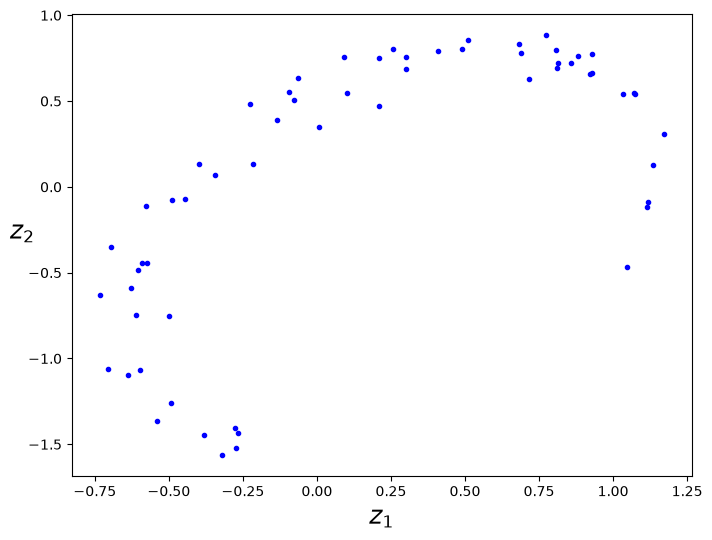

In [18]:


def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1): 
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5  #uneven distribution
    data = np.empty((m, 3))  #initialize 3d dataset
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise *  np.random.randn(m) / 2 #oval with noise
    data[:, 1] = np.sin(angles) * 0.7 + noise *  np.random.randn(m) / 2 
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise *  np.random.randn(m) 
    return data 

# Generate new sets of 3D data
X_train = generate_3d_data(60)
X_valid = generate_3d_data(500)

# Center both datasets using the training mean
train_mean = X_train.mean(axis=0, keepdims=True)

X_train = X_train - train_mean
X_valid = X_valid - train_mean

print(f"x_train: {X_train.shape}")
fig = px.scatter_3d(X_train, x=0, y=1, z=2, labels={"0": "x1", "1": "x2", "2": "x3"})
fig.show()

print(f"x_valid: {X_valid.shape}")

# Convert NumPy arrays to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_valid = torch.tensor(X_valid, dtype=torch.float32)

# Create datasets
train_set = TensorDataset(X_train, X_train)
valid_set = TensorDataset(X_valid, X_valid)

# Create data loaders
train_loader = DataLoader(
    train_set,
    batch_size=32,
    shuffle=True
)

valid_loader = DataLoader(
    valid_set,
    batch_size=32
)
print("ok")

#autoencoder
encoder = nn.Linear(3, 2)
decoder = nn.Linear(2, 3)
autoencoder = nn.Sequential(encoder, decoder).to(device)

optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.2)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(autoencoder, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=20)

codings = encoder(X_train.to(device)).detach().cpu().numpy()

%matplotlib inline
fig = plt.figure(figsize=(8, 6))
plt.plot(codings[:, 0], codings[:, 1], "b.")
plt.xlabel("$z_1$", fontsize=18)
plt.ylabel("$z_2$", fontsize=18, rotation=0)
plt.show()

## Problem 2
Train a deep autoencoder with the architecture presented on slide 33 and 
train it on MNIST data (images of handwritten digits). Present the original images of the first 5 elements of that data set and their reconstructed images.  

In [ ]:

# From slide 33:  build and train a stacked Autoencoder with 3 hidden layers and 1 output layer
stacked_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, 128), nn.ReLU(),
    nn.Linear(128, 32), nn.ReLU(),
)
stacked_decoder = nn.Sequential(
    nn.Linear(32, 128), nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28), nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28))
)
stacked_ae = nn.Sequential(stacked_encoder, stacked_decoder).to(device)

## Problem 3. 
Pass 4 images from the Fashion MNIST data set to the autoencoder trained in Problem 2 and present their reconstructed images. This is a demonstration of the anomaly detection. Calculate the loss value that such autoencoder produces for MNIST images and the loss values for Fashion MNIST images. Compare

## Problem 4. 
Please generate a 2D t-SNE display for MNIST data set similar to the display on slide 49. 

## Problem 5. 
Implement a convolutional denoising autoencoder with dropout layer and 
train it with MNIST data set. As the dropout parameter use 0.20. Produce 5 original images of random digits and their reconstructed images. Change the dropout parameter to 0.10 and compare new reconstructed images with the previous one. Just produce a qualitative assessment of the change in quality of the reconstructed images if any.  (20%) 

## Problem 6. 
Train a Variational Autoencoder on MNIST dataset with coding dimension 
of 2. Pick the mean coding values for two random images of two digits, for example 3 and 7. Create a set of 20 values uniformly distributed between those two coding values. Generate reconstruction images for every one of those coding values and present them as a 5x4 matrix